In [7]:
import numpy as np
import pandas as pd
import wfdb
import matplotlib.pyplot as plt

from tsfresh import extract_features, select_features
from tsfresh.feature_extraction import EfficientFCParameters
from tsfresh.utilities.dataframe_functions import impute

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

plt.rcParams["figure.figsize"] = (12, 4)

def create_windows(annotations, window_size=10000):
    annotations = annotations.dropna(subset=["start_consensus", "end_consensus", "quality_consensus"])
    windows = []
    for _, row in annotations.iterrows():
        start = int(row["start_consensus"])
        end = int(row["end_consensus"])
        quality = int(row["quality_consensus"])
        for window_start in range(start, end - window_size + 2, window_size):
            windows.append({
                "window_start": window_start,
                "window_end": window_start + window_size - 1,
                "annotation": quality
            })
    return pd.DataFrame(windows)




In [8]:
patient_ids = [
    '100001', '103001', '104001', '105001',
    '111001', '113001', '114001', '115001',
    '118001', '121001', '122001', '123001',
    '124001', '125001', '126001'
]

rows = []
duration_s = 60 * 20
fs_ecg = 1000  # BUT QDB ECG sampling frequency is 1000 Hz
cutoff = duration_s * fs_ecg

# 1. Load consensus quality annotations and create 10s windows
for record_id in patient_ids:
    ann_url = f"https://physionet.org/files/butqdb/1.0.0/{record_id}/{record_id}_ANN.csv"
    cols = [
        "start_1", "end_1", "quality_1",
        "start_2", "end_2", "quality_2",
        "start_3", "end_3", "quality_3",
        "start_consensus", "end_consensus", "quality_consensus"
    ]
    annotations = pd.read_csv(ann_url, header=None, names=cols)
    consensus_ann = annotations[["start_consensus", "end_consensus", "quality_consensus"]]
    consensus_ann = consensus_ann[consensus_ann["quality_consensus"].isin([1, 2, 3])].copy()

    cutoff_adjusted = cutoff + consensus_ann["start_consensus"].iloc[0]
    consensus_20min = consensus_ann[consensus_ann["start_consensus"] <= cutoff_adjusted].copy()
    consensus_20min["end_consensus"] = consensus_20min["end_consensus"].clip(upper=cutoff_adjusted)
    c_window = create_windows(consensus_20min)

    for _, w in c_window.iterrows():
        rows.append({
            "patient_id": str(record_id)[:3],
            "record_id": record_id,
            "start_sample": w["window_start"],
            "end_sample": w["window_end"],
            "quality": w["annotation"]
        })

# Keep first 60 windows per patient for equal representation
data = pd.DataFrame(rows).groupby("patient_id").head(60).reset_index(drop=True)
data["window_id"] = [f"{r}_{i:03d}" for i, r in enumerate(data["record_id"])]
data["label"] = (data["quality"] == 3).astype(int)  # 0 = Good (Q1/Q2), 1 = Poor (Q3)

# 2. Load ECG (1000 Hz) and Accelerometer (100 Hz) signals per record
data["ecg"] = None
data["acc_mag"] = None

for record_id in patient_ids:
    record_rows = data[data["record_id"] == record_id]
    start_sample = int(record_rows["start_sample"].min())
    end_sample = int(record_rows["end_sample"].max())
    pn_dir = f"butqdb/{record_id}"

    # Load ECG
    ecg_rec = wfdb.rdrecord(f"{record_id}_ECG", pn_dir=pn_dir, sampfrom=start_sample - 1, sampto=end_sample)
    ecg_sig = ecg_rec.p_signal[:, 0]

    # Load ACC and compute Euclidean magnitude across X, Y, Z axes
    acc_hdr = wfdb.rdheader(f"{record_id}_ACC", pn_dir=pn_dir)
    ratio = int(round(fs_ecg / acc_hdr.fs))
    acc_start_all = max(0, (start_sample - 1) // ratio)
    acc_end_all = max(acc_start_all + 1, end_sample // ratio)
    acc_rec = wfdb.rdrecord(f"{record_id}_ACC", pn_dir=pn_dir, sampfrom=acc_start_all, sampto=acc_end_all)
    acc_sig = np.linalg.norm(acc_rec.p_signal, axis=1)

    for idx, row in record_rows.iterrows():
        s_ecg = int(row["start_sample"]) - start_sample
        e_ecg = int(row["end_sample"]) - start_sample + 1
        data.at[idx, "ecg"] = ecg_sig[s_ecg:e_ecg]

        s_acc = max(0, (int(row["start_sample"]) - 1) // ratio - acc_start_all)
        e_acc = s_acc + (10000 // ratio)
        data.at[idx, "acc_mag"] = acc_sig[s_acc:e_acc]

print("Step 2 complete! Data loaded successfully.")
print("Dataset shape:", data.shape)
print("\nOverall class counts:")
print(data["label"].value_counts().rename({0: "Good (Q1/Q2)", 1: "Poor (Q3)"}))

# 3. Cohort & Class Distribution Audit per patient
per_patient_counts = pd.crosstab(data["patient_id"], data["label"])
per_patient_counts.columns = ["Good (0)", "Poor (1)"]
print("\nClass distribution per patient:")
display(per_patient_counts)

Step 2 complete! Data loaded successfully.
Dataset shape: (900, 9)

Overall class counts:
label
Good (Q1/Q2)    712
Poor (Q3)       188
Name: count, dtype: int64

Class distribution per patient:


,Good (0),Poor (1)
patient_id,,
100,60,0
103,60,0
104,60,0
105,0,60
111,60,0
113,60,0
114,5,55
115,60,0
118,60,0


Train vs. Test class balance:


,Train,Test
Good (0),600,112
Poor (1),120,68


Downsampled long-format shape: (3150000, 4)


Feature Extraction: 100%|██████████| 1800/1800 [00:01<00:00, 973.34it/s] 


Original feature count: 26
Selected feature count: 20
Selected ECG features (10), Selected ACC features (10)


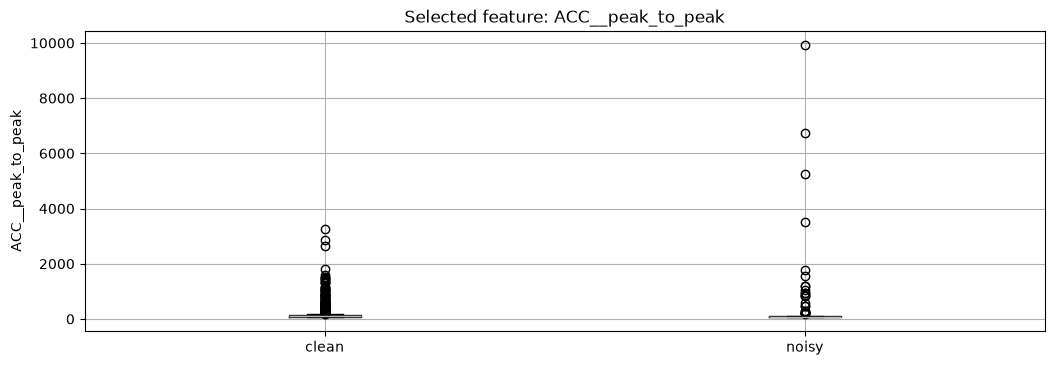

In [9]:
from scipy.signal import resample_poly
from tsfresh.feature_extraction import MinimalFCParameters

# 1. Balanced Group-wise split (Patients 114, 124, 125 in test -> 112 Good, 68 Poor) otherwise our model is not trained enough on the poor data:)
test_ids = ["114001", "124001", "125001"]
train_df = data[~data["record_id"].isin(test_ids)].copy()
test_df = data[data["record_id"].isin(test_ids)].copy()

assert not set(train_df["patient_id"]).intersection(set(test_df["patient_id"]))

split_summary = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
})
split_summary.index = ["Good (0)", "Poor (1)"]
print("Train vs. Test class balance:")
display(split_summary)

# 2. Safe anti-aliased downsampling of ECG (1000 Hz -> 250 Hz) otherwise it takes very long to load the ECG-data
def windows_to_tsfresh_long_fast(windows_df):
    long_parts = []
    for _, row in windows_df.iterrows():
        # Downsample ECG 1000 Hz -> 250 Hz using resample_poly
        ecg_250 = resample_poly(row["ecg"], up=1, down=4)
        tmp_ecg = pd.DataFrame({
            "id": row["window_id"],
            "time": np.arange(len(ecg_250)),
            "kind": "ECG",
            "value": ecg_250
        })
        tmp_acc = pd.DataFrame({
            "id": row["window_id"],
            "time": np.arange(len(row["acc_mag"])),
            "kind": "ACC",
            "value": row["acc_mag"]
        })
        long_parts.append(tmp_ecg)
        long_parts.append(tmp_acc)
    return pd.concat(long_parts, ignore_index=True)

long_df = windows_to_tsfresh_long_fast(data)
print("Downsampled long-format shape:", long_df.shape)

# 3. Extract MinimalFCParameters
X_minimal = extract_features(
    long_df,
    column_id="id",
    column_sort="time",
    column_kind="kind",
    column_value="value",
    default_fc_parameters=MinimalFCParameters(),
    n_jobs=0,
    disable_progressbar=False
)

# 4. Add curated quality features(derivative RMS, peak-to-peak, mean abs change)
curated_rows = []
for _, row in data.iterrows():
    ecg_w = resample_poly(row["ecg"], up=1, down=4)
    acc_w = row["acc_mag"]
    d_ecg = np.diff(ecg_w)
    d_acc = np.diff(acc_w)
    curated_rows.append({
        "window_id": row["window_id"],
        "ECG__peak_to_peak": np.ptp(ecg_w),
        "ECG__mean_abs_change": np.mean(np.abs(d_ecg)),
        "ECG__derivative_rms": np.sqrt(np.mean(d_ecg ** 2)),
        "ACC__peak_to_peak": np.ptp(acc_w),
        "ACC__mean_abs_change": np.mean(np.abs(d_acc)),
        "ACC__derivative_rms": np.sqrt(np.mean(d_acc ** 2))
    })

X_curated = pd.DataFrame(curated_rows).set_index("window_id")
X_all = X_minimal.join(X_curated)

# 5. Impute invalid values and align X and y 
X_imputed = X_all.copy()
impute(X_imputed)
y = data.set_index("window_id")["label"]
y_aligned = y.loc[X_imputed.index]

# Split into train and test feature matrices 
X_train = X_imputed.loc[train_df["window_id"]]
y_train = y_aligned.loc[train_df["window_id"]]

X_test = X_imputed.loc[test_df["window_id"]]
y_test = y_aligned.loc[test_df["window_id"]]

# 6. Supervised feature selection on TRAINING data only 
X_train_selected = select_features(X_train, y_train)
selected_names = X_train_selected.columns.tolist()
selected_ecg = [name for name in selected_names if name.startswith("ECG__")]
selected_acc = [name for name in selected_names if name.startswith("ACC__")]

print("Original feature count:", X_train.shape[1])
print("Selected feature count:", X_train_selected.shape[1])
print(f"Selected ECG features ({len(selected_ecg)}), Selected ACC features ({len(selected_acc)})")

# 7. Visualize top selected ACC feature
if len(selected_acc) > 0:
    feature_name = selected_acc[0]
    plot_df = X_train_selected[[feature_name]].join(y_train.rename("label"))
    plot_df["group"] = plot_df["label"].map({0: "clean", 1: "noisy"})

    plot_df.boxplot(column=feature_name, by="group")
    plt.suptitle("")
    plt.title(f"Selected feature: {feature_name}")
    plt.xlabel("")
    plt.ylabel(feature_name)
    plt.show()

Descriptive statistics between Good (0) and Poor (1) windows (Train set):


,feature,good_mean,good_sd,good_median,good_iqr,poor_mean,poor_sd,poor_median,poor_iqr
0,ECG__standard_deviation,366.185,287.437,303.748,169.229,232.512,1.566935e+03,31.086,11.845
1,ECG__variance,216573.976,1328507.899,92262.588,116064.593,2488887.958,1.926063e+07,979.675,699.542
2,ECG__root_mean_square,393.506,452.129,310.293,191.480,232.527,1.567007e+03,31.092,11.839
3,ACC__peak_to_peak,217.443,330.551,97.756,40.827,396.921,1.230051e+03,85.217,20.561
4,ACC__variance,2614.166,12046.550,226.056,106.518,6197.812,3.475177e+04,167.302,86.906
5,ACC__standard_deviation,28.584,42.428,15.035,3.356,32.600,7.196000e+01,12.934,3.181



Top 10 most influential features (Logistic Regression & Decision Tree):


C:\Users\corlu\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\corlu\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\corlu\anaconda3\Lib\site-packages\sklearn\linear_mo

,feature,lr_coefficient,abs_coef,tree_importance
19,ECG__mean_abs_change,3.6268,3.6268,0.0
1,ECG__variance,3.2262,3.2262,1.0
3,ECG__maximum,-3.2144,3.2144,0.0
5,ECG__absolute_maximum,-3.1091,3.1091,0.0
7,ECG__derivative_rms,3.0949,3.0949,0.0
8,ECG__median,2.2123,2.2123,0.0
4,ECG__peak_to_peak,-1.9434,1.9434,0.0
2,ECG__root_mean_square,-1.1647,1.1647,0.0
0,ECG__standard_deviation,-0.8925,0.8925,0.0
18,ACC__minimum,-0.7930,0.7930,0.0


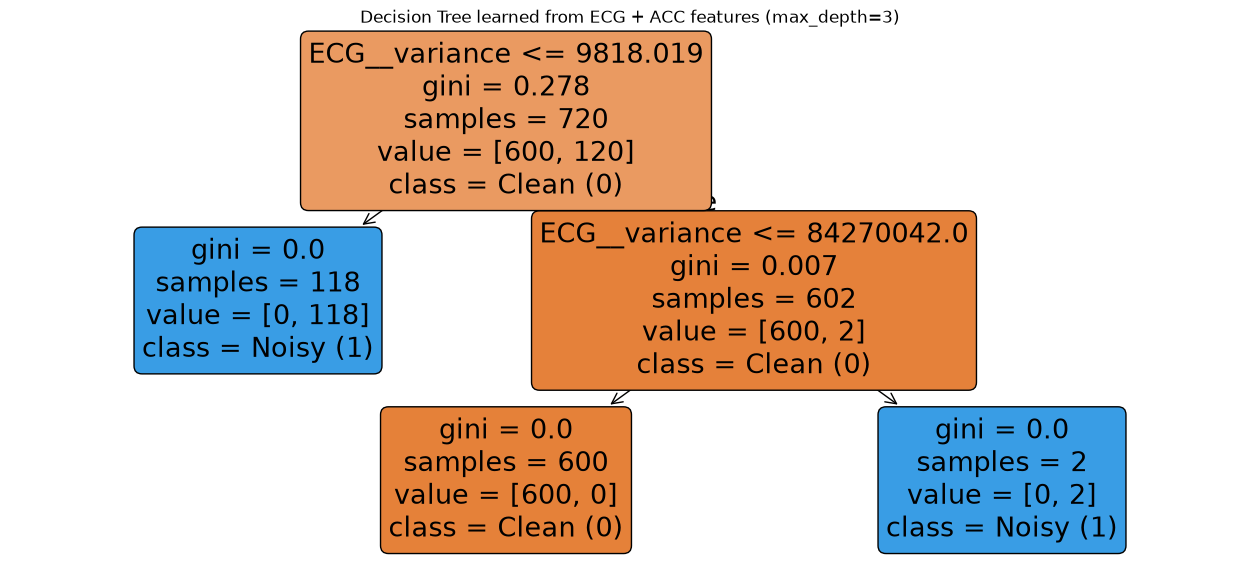

In [10]:
# 1. Define feature sets
ecg_features = selected_ecg
acc_features = selected_acc
both_features = selected_names  # Early fusion: ECG + ACC combined

# 2. Descriptive statistics by group
summary_rows = []
for feat in (ecg_features[:3] + acc_features[:3]):
    good_vals = X_train.loc[y_train == 0, feat]
    poor_vals = X_train.loc[y_train == 1, feat]
    summary_rows.append({
        "feature": feat,
        "good_mean": good_vals.mean(),
        "good_sd": good_vals.std(ddof=1),
        "good_median": good_vals.median(),
        "good_iqr": good_vals.quantile(0.75) - good_vals.quantile(0.25),
        "poor_mean": poor_vals.mean(),
        "poor_sd": poor_vals.std(ddof=1),
        "poor_median": poor_vals.median(),
        "poor_iqr": poor_vals.quantile(0.75) - poor_vals.quantile(0.25)
    })

stats_table = pd.DataFrame(summary_rows)
print("Descriptive statistics between Good (0) and Poor (1) windows (Train set):")
display(stats_table.round(3))

# 3. Fit Logistic Regression models
logistic_ecg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000))
])
logistic_ecg.fit(X_train[ecg_features], y_train)

logistic_acc = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000))
])
logistic_acc.fit(X_train[acc_features], y_train)

logistic_both = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000))
])
logistic_both.fit(X_train[both_features], y_train)

# 4. Fit Decision Tree model
tree_both = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_both.fit(X_train[both_features], y_train)

# 5. Inspect Model Coefficients & Feature Importances
coef_table = pd.DataFrame({
    "feature": both_features,
    "lr_coefficient": logistic_both.named_steps["model"].coef_[0],
    "abs_coef": np.abs(logistic_both.named_steps["model"].coef_[0]),
    "tree_importance": tree_both.feature_importances_
}).sort_values("abs_coef", ascending=False)

print("\nTop 10 most influential features (Logistic Regression & Decision Tree):")
display(coef_table.head(10).round(4))

# Visualize the Decision Tree rules
plt.figure(figsize=(16, 7))
plot_tree(
    tree_both,
    feature_names=both_features,
    class_names=["Clean (0)", "Noisy (1)"],
    filled=True,
    rounded=True
)
plt.title("Decision Tree learned from ECG + ACC features (max_depth=3)")
plt.show()

Model comparison on held-out test patients (threshold = 0.50):


,model,threshold,accuracy,sensitivity,specificity,false_positive_rate,TP,TN,FP,FN,ROC-AUC
0,ECG only (LR),0.5,0.922,0.794,1.0,0.0,54,112,0,14,0.828
1,ACC only (LR),0.5,0.628,0.015,1.0,0.0,1,112,0,67,0.814
2,Early fusion: ECG + ACC (LR),0.5,0.922,0.794,1.0,0.0,54,112,0,14,0.826
3,Late fusion: ECG + ACC (LR),0.5,0.917,0.779,1.0,0.0,53,112,0,15,0.821
4,Early fusion: ECG + ACC (Tree),0.5,0.633,0.029,1.0,0.0,2,112,0,66,0.515


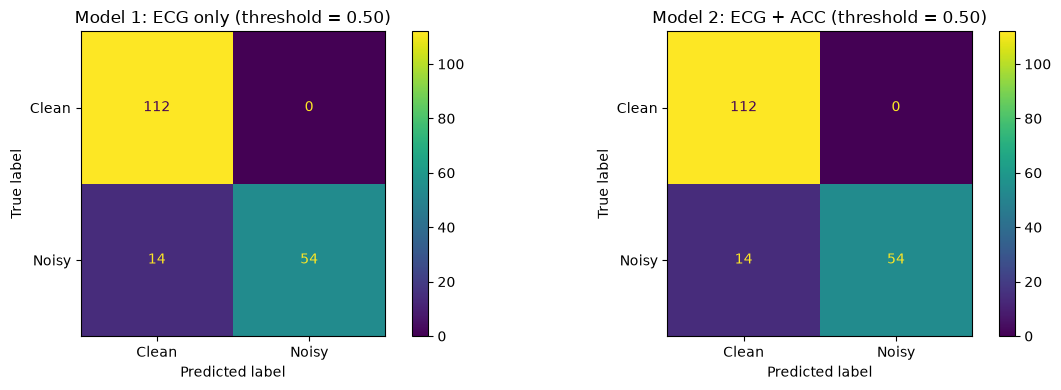

Threshold comparison — Model 1 (ECG only):


,threshold,accuracy,sensitivity,specificity,false_positive_rate,TP,TN,FP,FN,model
0,0.2,0.911,0.794,0.982,0.018,54,110,2,14,ECG only
1,0.3,0.922,0.794,1.000,0.000,54,112,0,14,ECG only
2,0.4,0.922,0.794,1.000,0.000,54,112,0,14,ECG only
3,0.5,0.922,0.794,1.000,0.000,54,112,0,14,ECG only
4,0.6,0.922,0.794,1.000,0.000,54,112,0,14,ECG only
5,0.7,0.922,0.794,1.000,0.000,54,112,0,14,ECG only
6,0.8,0.922,0.794,1.000,0.000,54,112,0,14,ECG only


Threshold comparison — Model 2 (ECG + ACC):


,threshold,accuracy,sensitivity,specificity,false_positive_rate,TP,TN,FP,FN,model
0,0.2,0.917,0.794,0.991,0.009,54,111,1,14,ECG + ACC
1,0.3,0.922,0.794,1.000,0.000,54,112,0,14,ECG + ACC
2,0.4,0.922,0.794,1.000,0.000,54,112,0,14,ECG + ACC
3,0.5,0.922,0.794,1.000,0.000,54,112,0,14,ECG + ACC
4,0.6,0.922,0.794,1.000,0.000,54,112,0,14,ECG + ACC
5,0.7,0.922,0.794,1.000,0.000,54,112,0,14,ECG + ACC
6,0.8,0.911,0.765,1.000,0.000,52,112,0,16,ECG + ACC


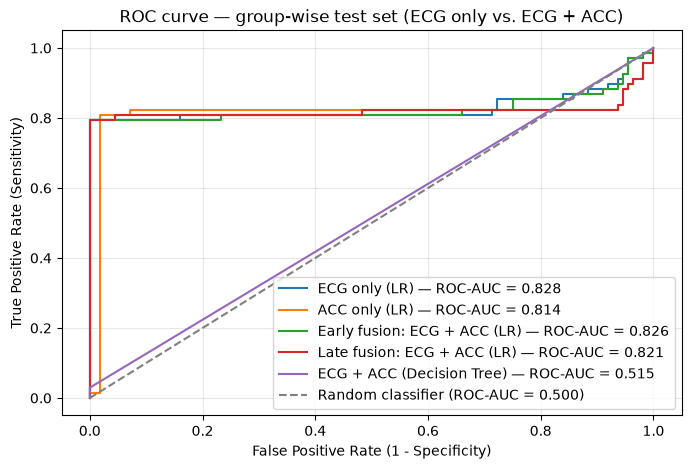

In [11]:
# 1. Obtain class-1 (Noisy / Q3) probabilities on the group-wise test set
prob_ecg = logistic_ecg.predict_proba(X_test[ecg_features])[:, 1]
prob_acc = logistic_acc.predict_proba(X_test[acc_features])[:, 1]
prob_both = logistic_both.predict_proba(X_test[both_features])[:, 1]  # Early fusion
prob_late = (prob_ecg + prob_acc) / 2                                # Late fusion (Lecture 10)
prob_tree = tree_both.predict_proba(X_test[both_features])[:, 1]

pred_ecg = (prob_ecg >= 0.50).astype(int)
pred_both = (prob_both >= 0.50).astype(int)

# 2. Helper function
def evaluate_at_threshold(y_true, probability, threshold=0.50):
    pred = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, pred),
        "sensitivity": sensitivity,
        "specificity": specificity,
        "false_positive_rate": 1 - specificity,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    }

# 3. Compare all models at default threshold 0.50 (Early vs Late fusion)
model_comparison = pd.DataFrame([
    {"model": "ECG only (LR)", **evaluate_at_threshold(y_test, prob_ecg, 0.50), "ROC-AUC": roc_auc_score(y_test, prob_ecg)},
    {"model": "ACC only (LR)", **evaluate_at_threshold(y_test, prob_acc, 0.50), "ROC-AUC": roc_auc_score(y_test, prob_acc)},
    {"model": "Early fusion: ECG + ACC (LR)", **evaluate_at_threshold(y_test, prob_both, 0.50), "ROC-AUC": roc_auc_score(y_test, prob_both)},
    {"model": "Late fusion: ECG + ACC (LR)", **evaluate_at_threshold(y_test, prob_late, 0.50), "ROC-AUC": roc_auc_score(y_test, prob_late)},
    {"model": "Early fusion: ECG + ACC (Tree)", **evaluate_at_threshold(y_test, prob_tree, 0.50), "ROC-AUC": roc_auc_score(y_test, prob_tree)},
])
print("Model comparison on held-out test patients (threshold = 0.50):")
display(model_comparison.round(3))

# 4. Confusion matrices at default threshold 0.50
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_ecg, display_labels=["Clean", "Noisy"], ax=ax[0]
)
ax[0].set_title("Model 1: ECG only (threshold = 0.50)")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_both, display_labels=["Clean", "Noisy"], ax=ax[1]
)
ax[1].set_title("Model 2: ECG + ACC (threshold = 0.50)")

plt.tight_layout()
plt.show()

# 5. Evaluate multiple thresholds
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_table_ecg = pd.DataFrame([
    evaluate_at_threshold(y_test, prob_ecg, threshold=t) for t in thresholds
])
threshold_table_ecg["model"] = "ECG only"

threshold_table_both = pd.DataFrame([
    evaluate_at_threshold(y_test, prob_both, threshold=t) for t in thresholds
])
threshold_table_both["model"] = "ECG + ACC"

print("Threshold comparison — Model 1 (ECG only):")
display(threshold_table_ecg.round(3))

print("Threshold comparison — Model 2 (ECG + ACC):")
display(threshold_table_both.round(3))

# 6. ROC curves and ROC-AUC on the same figure
plt.figure(figsize=(8, 5))
for name, probs in [
    ("ECG only (LR)", prob_ecg),
    ("ACC only (LR)", prob_acc),
    ("Early fusion: ECG + ACC (LR)", prob_both),
    ("Late fusion: ECG + ACC (LR)", prob_late),
    ("ECG + ACC (Decision Tree)", prob_tree)
]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} — ROC-AUC = {auc:.3f}")

plt.plot([0, 1], [0, 1], "--", color="gray", label="Random classifier (ROC-AUC = 0.500)")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC curve — group-wise test set (ECG only vs. ECG + ACC)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
import joblib
from pathlib import Path

docker_dir = Path("docker_project")
docker_dir.mkdir(exist_ok=True)

# 1. Save fitted model (Early fusion Logistic Regression)
joblib.dump(logistic_both, docker_dir / "model.joblib")

# 2. Save held-out test set (features + true label)
test_export = X_test[both_features].copy()
test_export["label"] = y_test
test_export.to_csv(docker_dir / "test.csv", index=False)

# 3. Create run_project.py
run_script = '''import joblib
import pandas as pd
from sklearn.metrics import confusion_matrix

model = joblib.load("model.joblib")
test = pd.read_csv("test.csv")

X_test = test.drop(columns=["label"])
y_test = test["label"]

predictions = model.predict(X_test)
matrix = confusion_matrix(y_test, predictions, labels=[0, 1])

cm_df = pd.DataFrame(
    matrix,
    index=["Actual 0 (Clean)", "Actual 1 (Noisy)"],
    columns=["Predicted 0", "Predicted 1"]
)
print("Confusion Matrix on held-out test set:")
print(cm_df)
'''
(docker_dir / "run_project.py").write_text(run_script)

# 4. Create requirements.txt with exact environment versions
reqs = "\n".join([
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"joblib=={joblib.__version__}"
]) + "\n"
(docker_dir / "requirements.txt").write_text(reqs)

# 5. Create Dockerfile
dockerfile_content = '''FROM python:3.11-slim

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY model.joblib test.csv run_project.py ./

CMD ["python", "run_project.py"]
'''
(docker_dir / "Dockerfile").write_text(dockerfile_content)

# 6. Create README.md with build/run commands and expected confusion matrix
expected_cm = confusion_matrix(y_test, logistic_both.predict(X_test[both_features]), labels=[0, 1])
readme_content = f'''# ECG Quality Classification — Docker Evaluation

## Build and run commands
```bash
cd docker_project
docker build -t semester-project .
docker run --rm semester-project

_IncompleteInputError: incomplete input (1195387589.py, line 64)